<img src="img/capa.png" alt="Capa — Análise de Sentimento das Atas do COPOM" width="900"/>

# 🏦 Análise de Sentimento & Postura Monetária nas Atas do COPOM (2012–2026)

**Autor:** Dr. Silvio da Rosa Paula — Doutor em Economia Aplicada | Cientista de Dados  
**Portfólio:** [GitHub](https://github.com/silviopaula) • [LinkedIn](https://www.linkedin.com/in/silvio-paula/)

---

## 🎯 Objetivo e Evolução Metodológica

Os bancos centrais modernos conduzem a política monetária não apenas alterando a taxa básica de juros, mas também gerenciando expectativas por meio da sua **comunicação oficial** (*forward guidance*). Neste projeto, aplicamos **Processamento de Linguagem Natural (NLP)** e **Econometria de Séries Temporais** sobre **111 atas oficiais do COPOM** (Reuniões **#171 a #282**, de **dezembro/2012 a novembro/2026**), integradas às séries oficiais da **Taxa Selic (SGS 432)** e do **IPCA (SGS 433)** do Banco Central do Brasil.

### Por que ir além do simples "Positivo vs. Negativo"?
Na literatura empírica de comunicação de bancos centrais (Lucca & Trebbi, 2009; Hansen & McMahon, 2016; BIS), avaliar atas apenas por polaridade genérica (*otimista vs. pessimista*) mistura sinais distintos: uma economia aquecida pode ter tom "positivo" de atividade e, ao mesmo tempo, exigir **alta de juros** (*postura contracionista*)! Por isso, construímos uma **arquitetura NLP de dupla dimensão** (encapsulada em [`src/copom_nlp.py`](./src/copom_nlp.py)):

1. **Sentimento Financeiro (estilo Loughran–McDonald)** + **Índice de Incerteza (%)**, com tratamento explícito de **janela de negação** (*"not", "no", "less"*).
2. **Índice *Hawkish–Dovish* (Postura de Política Monetária)**: mede o balanço entre termos/bigramas contracionistas (*tightening, upside risks, inflationary pressures, deanchoring, restrictive*) e expansionistas (*easing, disinflation, economic slack, cuts, moderation*).
3. **Modelagem de Tópicos (TF-IDF + NMF)**: revela automaticamente os grandes ciclos temáticos do COPOM nos últimos 14 anos.
4. **Validação Macroeconômica e Preditiva (*Walk-Forward Out-of-Sample*)**: alinhamento exato por **data de cada reunião** (sem duplicação diária!) para testar se o texto da ata $t$ antecipa a decisão da **Selic na reunião seguinte ($t+1$)**.
5. **Comparação Institucional por Presidência do BCB**: Tombini, Goldfajn, Campos Neto e Galípolo (atualizado até novembro/2026).

---

## 1. Carregamento do Corpus Atualizado (111 Atas: 2012–2026) e Alinhamento Macroeconômico

Todos os dados oficiais do Banco Central do Brasil foram consolidados em formato aberto na pasta `data/` (atualizados até **novembro/2026**, Reunião **#282**):
- [`data/atas_copom.csv.gz`](./data/atas_copom.csv.gz): texto integral em inglês das 111 atas oficiais do COPOM (`2012-12-12` a `2026-11-04`).
- [`data/selic_diaria.csv`](./data/selic_diaria.csv): histórico diário da Taxa Selic Meta (SGS 432, `2012-01` a `2026-11`).
- [`data/macro_selic_ipca.csv`](./data/macro_selic_ipca.csv): série mensal de Selic e IPCA (mensal e acumulado em 12 meses, SGS 433).

> **Cuidado crucial de Engenharia de Dados (Zero *Data Leakage* & Zero Duplicação):** em vez de cruzar atas com a Selic diária truncada por mês (o que multiplicaria cada ata por ~30 linhas repetidas), alinhamos cada reunião $t$ exatamente à **Selic Meta definida naquela reunião** ($\text{Selic}_t$), à **variação decidida na reunião** ($\Delta \text{Selic}_t$), à **decisão da reunião seguinte** ($\Delta \text{Selic}_{t+1}$) e ao **IPCA 12m já divulgado antes da reunião** ($m-1$).

In [1]:
import warnings
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    confusion_matrix,
    f1_score,
)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from statsmodels.tsa.stattools import grangercausalitytests

from src.copom_nlp import (
    extract_top_policy_terms,
    fit_copom_topics,
    map_bcb_president,
    score_copom_minute,
)

warnings.filterwarnings("ignore")

plt.rcParams.update(
    {
        "figure.dpi": 120,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "grid.alpha": 0.25,
        "font.size": 10,
    }
)

DATA_DIR = Path("data")
IMG_DIR = Path("img")
OUT_DIR = Path("outputs")
IMG_DIR.mkdir(exist_ok=True)
OUT_DIR.mkdir(exist_ok=True)

# 1. Carregar corpus de 111 atas e séries macro atualizadas até nov/2026
df_atas = pd.read_csv(DATA_DIR / "atas_copom.csv.gz", parse_dates=["data_reuniao"]).sort_values("data_reuniao").reset_index(drop=True)
df_selic = pd.read_csv(DATA_DIR / "selic_diaria.csv", parse_dates=["data"]).sort_values("data").reset_index(drop=True)
df_macro = pd.read_csv(DATA_DIR / "macro_selic_ipca.csv", parse_dates=["data"]).sort_values("data").reset_index(drop=True)

# 2. Pontuação NLP das 111 atas (Loughran-McDonald + Incerteza + Índice Hawkish-Dovish)
scores_df = pd.DataFrame([score_copom_minute(txt) for txt in df_atas["conteudo"]])
df = pd.concat([df_atas.drop(columns=["conteudo"]), scores_df], axis=1)
df["presidente_bcb"] = map_bcb_president(df["data_reuniao"])

# 3. Alinhamento exato de cada reunião com Selic pré/pós-reunião e IPCA 12m disponível
df["data_pos"] = df["data_reuniao"] + pd.Timedelta(days=3)
df["data_pre"] = df["data_reuniao"] - pd.Timedelta(days=3)

df = (
    pd.merge_asof(
        df.sort_values("data_pos"),
        df_selic.rename(columns={"selic": "selic_meta"}),
        left_on="data_pos",
        right_on="data",
        direction="backward",
    )
    .drop(columns=["data"])
)
df = (
    pd.merge_asof(
        df.sort_values("data_pre"),
        df_selic.rename(columns={"selic": "selic_anterior"}),
        left_on="data_pre",
        right_on="data",
        direction="backward",
    )
    .drop(columns=["data"])
    .sort_values("data_reuniao")
    .reset_index(drop=True)
)

df["delta_selic_t"] = (df["selic_meta"] - df["selic_anterior"]).round(2)
df["delta_selic_next"] = df["delta_selic_t"].shift(-1)

# IPCA 12m do mês imediatamente anterior à reunião (informação pública disponível no momento da decisão)
df["mes_ipca"] = (df["data_reuniao"] - pd.DateOffset(months=1)).dt.to_period("M").dt.to_timestamp()
df = pd.merge(
    df,
    df_macro[["data", "ipca_mensal", "ipca_12m"]].rename(columns={"data": "mes_ipca"}),
    on="mes_ipca",
    how="left",
)
df["juro_real_expost"] = (df["selic_meta"] - df["ipca_12m"]).round(2)

# Classificação interpretável da postura Hawkish-Dovish (tercis / limiar ±0,15)
df["postura_copom"] = np.where(
    df["indice_hawkish"] >= 0.15,
    "Hawkish (Contracionista)",
    np.where(df["indice_hawkish"] <= -0.15, "Dovish (Expansionista)", "Neutro / Transição"),
)

# Salva painel analítico consolidado (sem texto bruto) em outputs/
export_cols = [
    "reuniao_num", "data_reuniao", "presidente_bcb", "n_palavras",
    "sentimento_lm", "incerteza_pct", "indice_hawkish", "postura_copom",
    "selic_meta", "delta_selic_t", "delta_selic_next", "ipca_12m", "juro_real_expost",
]
df[export_cols].to_csv(OUT_DIR / "copom_nlp_macro_panel.csv", index=False)

print(
    f"Corpus consolidado: {len(df)} atas (#{df['reuniao_num'].min()} a #{df['reuniao_num'].max()}) | "
    f"Período: {df['data_reuniao'].min():%d/%m/%Y} a {df['data_reuniao'].max():%d/%m/%Y}"
)
print(f"Última ata: #{df['reuniao_num'].iloc[-1]} ({df['data_reuniao'].iloc[-1]:%d/%m/%Y}) | Selic={df['selic_meta'].iloc[-1]:.2f}% | IPCA 12m={df['ipca_12m'].iloc[-1]:.2f}% | Hawkish={df['indice_hawkish'].iloc[-1]:+.3f}")
display(df[["n_palavras", "sentimento_lm", "incerteza_pct", "indice_hawkish", "selic_meta", "delta_selic_t", "ipca_12m"]].describe().T[["count", "mean", "std", "min", "50%", "max"]].round(3))

Corpus consolidado: 111 atas (#171 a #282) | Período: 12/12/2012 a 04/11/2026
Última ata: #282 (04/11/2026) | Selic=13.75% | IPCA 12m=4.63% | Hawkish=+0.365


,count,mean,std,min,50%,max
n_palavras,111.0,3047.973,1680.160,1521.000,2479.000,8155.000
sentimento_lm,111.0,0.030,0.279,-0.591,-0.017,0.535
incerteza_pct,111.0,2.439,0.903,0.637,2.615,4.446
indice_hawkish,111.0,0.053,0.412,-0.879,0.149,0.845
selic_meta,111.0,10.162,3.947,2.000,11.000,15.000
delta_selic_t,111.0,0.068,0.433,-0.750,0.000,1.500
ipca_12m,111.0,5.790,2.418,1.877,5.131,12.131


---

## 2. Sentimento Financeiro (LM) vs. Postura Monetária (*Hawkish–Dovish*)

Vamos visualizar lado a lado:
1. A trajetória do **Índice *Hawkish–Dovish*** (suavizado em média móvel de 3 reuniões) comparada à **Taxa Selic Meta (%)** e ao **IPCA acumulado em 12 meses (%)** ao longo de **14 anos** (`2012–2026`).
2. A transparência lexicográfica: quais **expressões de política monetária** (*bigramas/frases*) mais apareceram nas 111 atas nos polos *Hawkish* e *Dovish*.

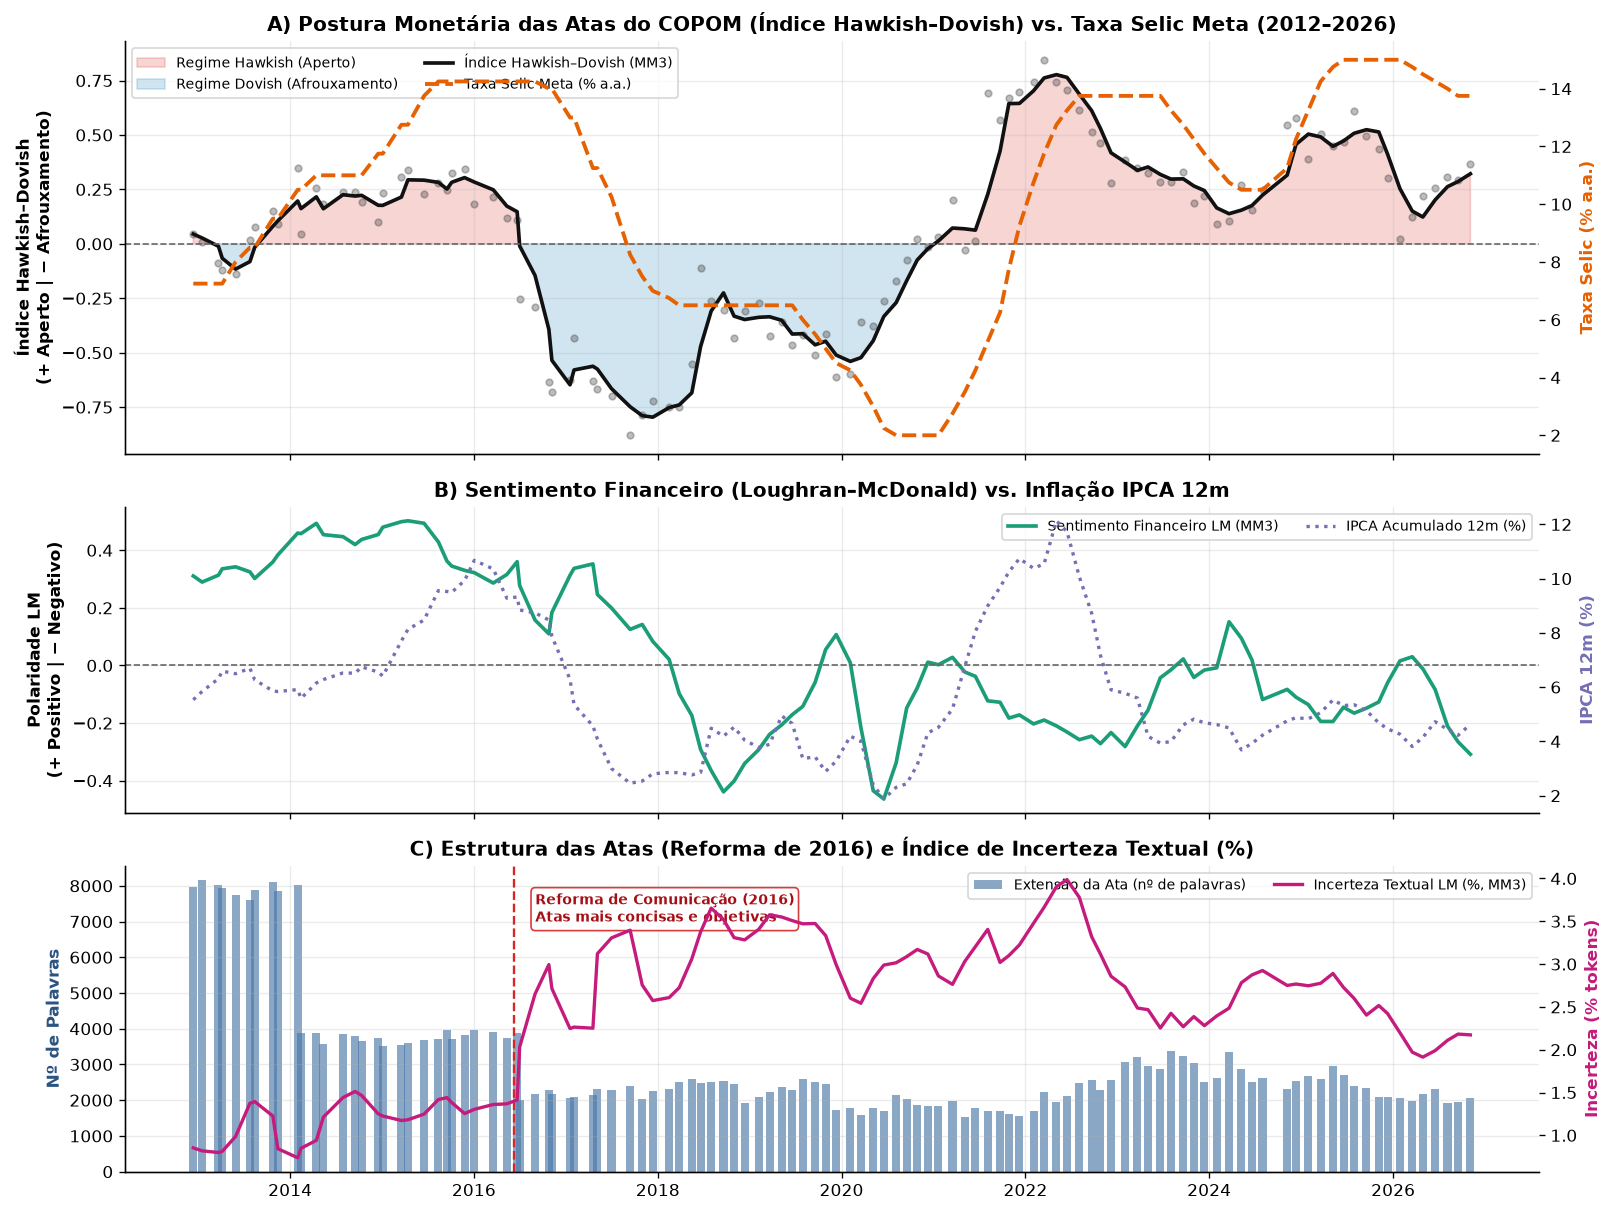

In [2]:
# Gráfico 1 — Evolução do Índice Hawkish-Dovish vs. Taxa Selic e IPCA 12m (2012-2026)
df["hawkish_mm3"] = df["indice_hawkish"].rolling(3, min_periods=1).mean()
df["sentimento_mm3"] = df["sentimento_lm"].rolling(3, min_periods=1).mean()

fig, axes = plt.subplots(3, 1, figsize=(13.5, 10.2), sharex=True, gridspec_kw={"height_ratios": [1.35, 1.0, 1.0]})

# Painel A: Índice Hawkish-Dovish vs Selic (eixo secundário)
ax1 = axes[0]
ax1.fill_between(df["data_reuniao"], 0, df["hawkish_mm3"], where=df["hawkish_mm3"] >= 0, color="#d73027", alpha=0.20, interpolate=True, label="Regime Hawkish (Aperto)")
ax1.fill_between(df["data_reuniao"], 0, df["hawkish_mm3"], where=df["hawkish_mm3"] < 0, color="#2b8cbe", alpha=0.22, interpolate=True, label="Regime Dovish (Afrouxamento)")
ax1.plot(df["data_reuniao"], df["hawkish_mm3"], color="#111111", linewidth=2.2, label="Índice Hawkish–Dovish (MM3)")
ax1.scatter(df["data_reuniao"], df["indice_hawkish"], color="#444444", s=16, alpha=0.35)
ax1.axhline(0, color="#666666", linestyle="--", linewidth=1.0)
ax1.set_ylabel("Índice Hawkish–Dovish\n(+ Aperto | − Afrouxamento)", fontweight="bold")
ax1.set_title("A) Postura Monetária das Atas do COPOM (Índice Hawkish–Dovish) vs. Taxa Selic Meta (2012–2026)", fontweight="bold")

ax1_r = ax1.twinx()
ax1_r.plot(df["data_reuniao"], df["selic_meta"], color="#e66101", linewidth=2.3, linestyle="--", label="Taxa Selic Meta (% a.a.)")
ax1_r.set_ylabel("Taxa Selic (% a.a.)", color="#e66101", fontweight="bold")
ax1_r.spines["top"].set_visible(False)
ax1_r.grid(False)

h1, l1 = ax1.get_legend_handles_labels()
h2, l2 = ax1_r.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, loc="upper left", ncol=2, fontsize=8.3, frameon=True)

# Painel B: Sentimento Financeiro Loughran-McDonald vs IPCA 12m
ax2 = axes[1]
ax2.plot(df["data_reuniao"], df["sentimento_mm3"], color="#1b9e77", linewidth=2.2, label="Sentimento Financeiro LM (MM3)")
ax2.axhline(0, color="#666666", linestyle="--", linewidth=1.0)
ax2.set_ylabel("Polaridade LM\n(+ Positivo | − Negativo)", fontweight="bold")
ax2.set_title("B) Sentimento Financeiro (Loughran–McDonald) vs. Inflação IPCA 12m", fontweight="bold")

ax2_r = ax2.twinx()
ax2_r.plot(df["data_reuniao"], df["ipca_12m"], color="#7570b3", linewidth=2.0, linestyle=":", label="IPCA Acumulado 12m (%)")
ax2_r.set_ylabel("IPCA 12m (%)", color="#7570b3", fontweight="bold")
ax2_r.spines["top"].set_visible(False)
ax2_r.grid(False)

h3, l3 = ax2.get_legend_handles_labels()
h4, l4 = ax2_r.get_legend_handles_labels()
ax2.legend(h3 + h4, l3 + l4, loc="upper right", ncol=2, fontsize=8.5, frameon=True)

# Painel C: Comprimento das atas (reforma de comunicação de 2016) + Índice de Incerteza
ax3 = axes[2]
ax3.bar(df["data_reuniao"], df["n_palavras"], width=32, color="#4c78a8", alpha=0.65, label="Extensão da Ata (nº de palavras)")
ax3.axvline(pd.Timestamp("2016-06-09"), color="#d62728", linestyle="--", linewidth=1.4)
ax3.text(
    pd.Timestamp("2016-09-01"),
    7000,
    "Reforma de Comunicação (2016)\nAtas mais concisas e objetivas",
    color="#a50f15",
    fontsize=8.5,
    fontweight="bold",
    bbox={"boxstyle": "round,pad=0.3", "fc": "white", "ec": "#d62728", "alpha": 0.9},
)
ax3.set_ylabel("Nº de Palavras", color="#2c5480", fontweight="bold")
ax3.set_title("C) Estrutura das Atas (Reforma de 2016) e Índice de Incerteza Textual (%)", fontweight="bold")

ax3_r = ax3.twinx()
ax3_r.plot(df["data_reuniao"], df["incerteza_pct"].rolling(3, min_periods=1).mean(), color="#c51b7d", linewidth=2.0, label="Incerteza Textual LM (%, MM3)")
ax3_r.set_ylabel("Incerteza (% tokens)", color="#c51b7d", fontweight="bold")
ax3_r.spines["top"].set_visible(False)
ax3_r.grid(False)

h5, l5 = ax3.get_legend_handles_labels()
h6, l6 = ax3_r.get_legend_handles_labels()
ax3.legend(h5 + h6, l5 + l6, loc="upper right", ncol=2, fontsize=8.5, frameon=True)

ax3.xaxis.set_major_locator(mdates.YearLocator(2))
ax3.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))

plt.tight_layout()
plt.savefig(IMG_DIR / "evolucao_hawkish_sentimento_selic.png", dpi=150, bbox_inches="tight")
plt.show()

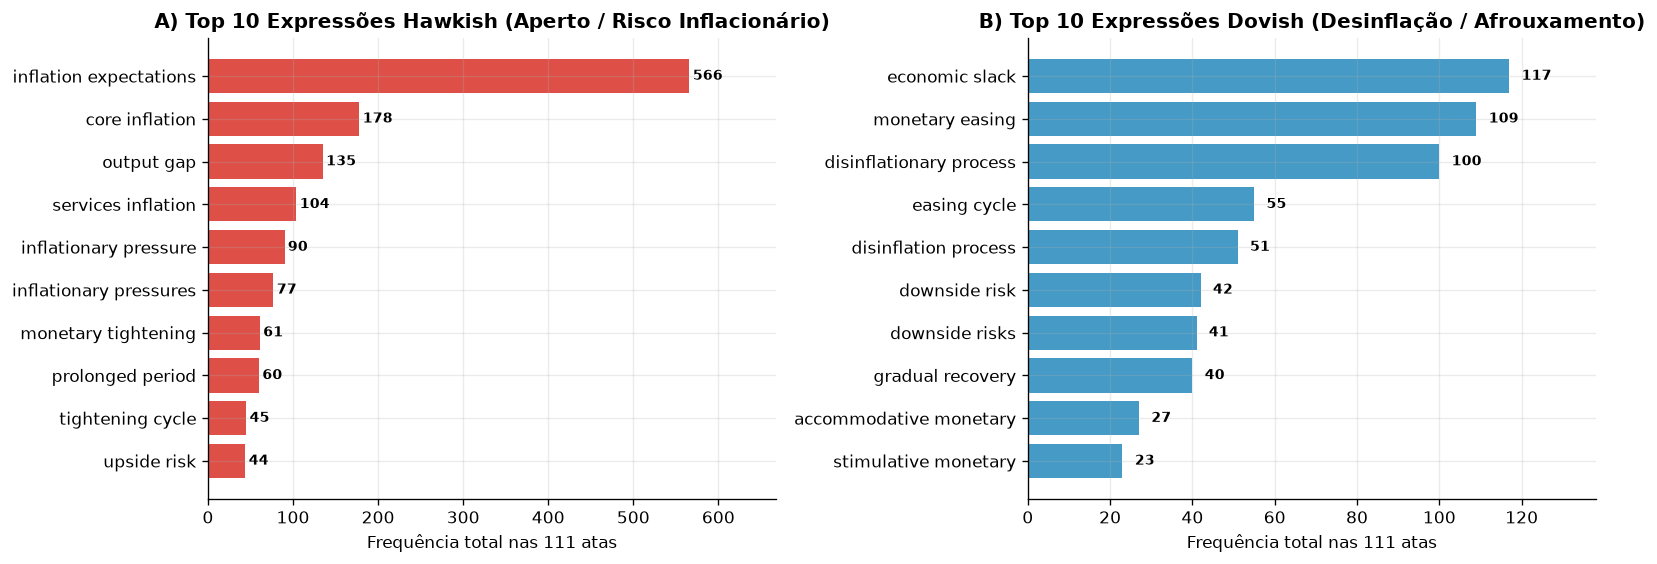

In [3]:
# Gráfico 2 — Expressões de Política Monetária mais frequentes no Corpus (Hawkish vs. Dovish)
df_hk_top, df_dv_top = extract_top_policy_terms(df_atas["conteudo"], top_n=10)

fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.8))

axes[0].barh(df_hk_top["expressao"][::-1], df_hk_top["frequencia"][::-1], color="#d73027", alpha=0.85)
axes[0].set_title("A) Top 10 Expressões Hawkish (Aperto / Risco Inflacionário)", fontweight="bold")
axes[0].set_xlabel("Frequência total nas 111 atas")
for idx, val in enumerate(df_hk_top["frequencia"][::-1]):
    axes[0].text(val + 4, idx, str(val), va="center", fontsize=8.5, fontweight="bold")
axes[0].set_xlim(0, df_hk_top["frequencia"].max() * 1.18)

axes[1].barh(df_dv_top["expressao"][::-1], df_dv_top["frequencia"][::-1], color="#2b8cbe", alpha=0.88)
axes[1].set_title("B) Top 10 Expressões Dovish (Desinflação / Afrouxamento)", fontweight="bold")
axes[1].set_xlabel("Frequência total nas 111 atas")
for idx, val in enumerate(df_dv_top["frequencia"][::-1]):
    axes[1].text(val + 3, idx, str(val), va="center", fontsize=8.5, fontweight="bold")
axes[1].set_xlim(0, df_dv_top["frequencia"].max() * 1.18)

plt.tight_layout()
plt.savefig(IMG_DIR / "top_expressoes_hawkish_dovish.png", dpi=150, bbox_inches="tight")
plt.show()

---

## 3. Descoberta Não-Supervisionada de Tópicos nas Atas (TF-IDF + NMF)

Além dos dicionários financeiros, aplicamos **TF-IDF + Fatoração de Matrizes Não-Negativas (NMF)** para descobrir, de forma puramente orientada aos dados, como os grandes temas econômicos se revezaram na agenda do COPOM entre 2012 e 2026.

T1: Reformas & Ancoragem Fiscal              -> baseline, reforms, adjustments economy, evolution, conduct, conduct monetary, anchored, adjustments
T2: Atividade, Indústria & Preços (2012–15)  -> index, increased, decreased, goods, production, seasonally, billion, reached
T3: Mercado de Trabalho & Desancoragem       -> labor, labor market, morning, disinflation, reference scenario, slowdown, conduct, deanchored
T4: Pandemia & Estímulo Monetário            -> pandemic, baseline, baseline scenario, monetary stimulus, stimulus, recovery, oliveira, slack
T5: Desinflação & Ciclo de Cortes            -> easing, monetary easing, forecasts, disinflation, cycle, agreed, possible, conditional


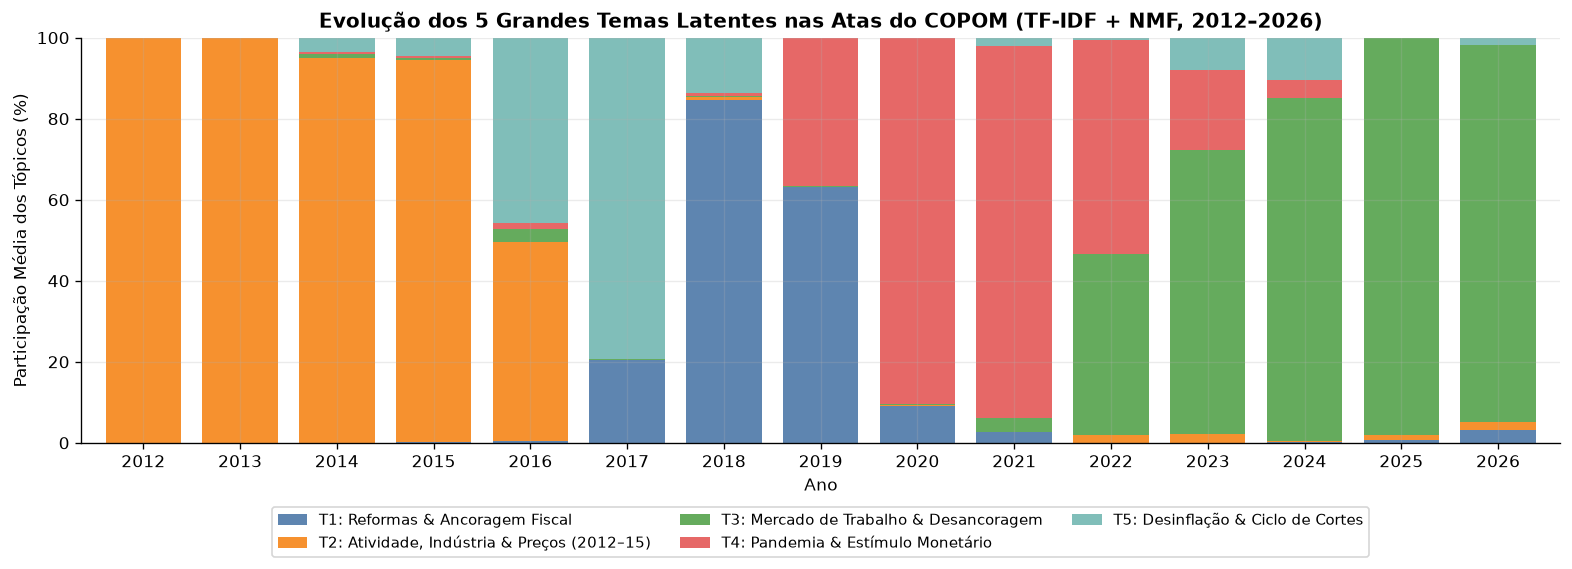

In [4]:
df_topics, topic_meta = fit_copom_topics(df_atas["conteudo"], n_topics=5, random_state=42)

# Rotulação automática interpretável baseada nos termos mais fortes de cada tópico
def _label_topic(terms: list[str], idx: int) -> str:
    joined = " ".join(terms)
    if "pandemic" in joined or "stimulus" in joined:
        return f"T{idx+1}: Pandemia & Estímulo Monetário"
    if "labor" in joined or "deanchored" in joined or "gap" in joined:
        return f"T{idx+1}: Mercado de Trabalho & Desancoragem"
    if "easing" in joined or "disinflation" in joined:
        return f"T{idx+1}: Desinflação & Ciclo de Cortes"
    if "reforms" in joined or "adjustments" in joined or "anchored" in joined:
        return f"T{idx+1}: Reformas & Ancoragem Fiscal"
    if "index" in joined or "production" in joined or "goods" in joined:
        return f"T{idx+1}: Atividade, Indústria & Preços (2012–15)"
    return f"T{idx+1}: {', '.join(terms[:3]).title()}"

topic_labels = [_label_topic(tm["top_terms"], tm["topic_id"]) for tm in topic_meta]
for lbl, tm in zip(topic_labels, topic_meta):
    print(f"{lbl:44s} -> {', '.join(tm['top_terms'])}")

df_topics.columns = topic_labels
df_topics_time = pd.concat([df[["data_reuniao"]], df_topics], axis=1)
df_topics_time["ano"] = df_topics_time["data_reuniao"].dt.year
df_topics_yr = df_topics_time.groupby("ano")[topic_labels].mean() * 100.0

# Gráfico 3 — Evolução anual dos 5 tópicos dominantes nas atas (2012–2026)
fig, ax = plt.subplots(figsize=(13.2, 4.9))
pal_topics = ["#4c78a8", "#f58518", "#54a24b", "#e45756", "#72b7b2"]
df_topics_yr.plot(kind="bar", stacked=True, color=pal_topics, width=0.78, alpha=0.9, ax=ax)
ax.set_ylabel("Participação Média dos Tópicos (%)")
ax.set_xlabel("Ano")
ax.set_ylim(0, 100)
ax.set_title("Evolução dos 5 Grandes Temas Latentes nas Atas do COPOM (TF-IDF + NMF, 2012–2026)", fontweight="bold")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.14), ncol=3, fontsize=8.8, frameon=True)
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(IMG_DIR / "topicos_nmf_copom_evolucao.png", dpi=150, bbox_inches="tight")
plt.show()

---

## 4. Validação Econométrica: Correlação Cruzada (CCF) e Relação com Selic e IPCA

Aqui testamos formalmente **qual métrica textual realmente conversa com a política monetária brasileira**:
- Comparamos a correlação contemporânea e defasada do **Índice *Hawkish–Dovish*** vs. **Sentimento Financeiro LM** contra:
  - Nível da **Selic Meta** ($\text{Selic}_t$);
  - Decisão contemporânea ($\Delta \text{Selic}_t$);
  - **Próxima decisão do COPOM** ($\Delta \text{Selic}_{t+1}$ — o teste decisivo de *forward guidance*!);
  - **IPCA acumulado em 12 meses**.

=== CORRELAÇÕES ENTRE MÉTRICAS NLP E VARIÁVEIS MACROECONÔMICAS (111 REUNIÕES) ===


,Métrica NLP,Selic Meta (t),Δ Selic (t),Δ Selic (t+1),IPCA 12m
0,Índice Hawkish–Dovish (Política Monetária),+0.457*** (p=0.000),+0.473*** (p=0.000),+0.442*** (p=0.000),+0.537*** (p=0.000)
1,Sentimento Financeiro (Loughran–McDonald),+0.221** (p=0.020),-0.138 (p=0.149),-0.104 (p=0.279),+0.262*** (p=0.005)
2,Índice de Incerteza Textual (%),-0.305*** (p=0.001),+0.245*** (p=0.010),+0.211** (p=0.027),-0.164* (p=0.085)



=== CAUSALIDADE DE GRANGER: ÍNDICE HAWKISH → VARIAÇÃO DA SELIC (ΔSelic) ===

Granger Causality
number of lags (no zero) 1
ssr based F test:         F=0.1805  , p=0.6718  , df_denom=107, df_num=1
ssr based chi2 test:   chi2=0.1855  , p=0.6667  , df=1
likelihood ratio test: chi2=0.1854  , p=0.6668  , df=1
parameter F test:         F=0.1805  , p=0.6718  , df_denom=107, df_num=1

Granger Causality
number of lags (no zero) 2
ssr based F test:         F=0.9281  , p=0.3985  , df_denom=104, df_num=2
ssr based chi2 test:   chi2=1.9455  , p=0.3780  , df=2
likelihood ratio test: chi2=1.9284  , p=0.3813  , df=2
parameter F test:         F=0.9281  , p=0.3985  , df_denom=104, df_num=2

Granger Causality
number of lags (no zero) 3
ssr based F test:         F=1.5244  , p=0.2128  , df_denom=101, df_num=3
ssr based chi2 test:   chi2=4.8902  , p=0.1800  , df=3
likelihood ratio test: chi2=4.7827  , p=0.1884  , df=3
parameter F test:         F=1.5244  , p=0.2128  , df_denom=101, df_num=3

Granger Causalit

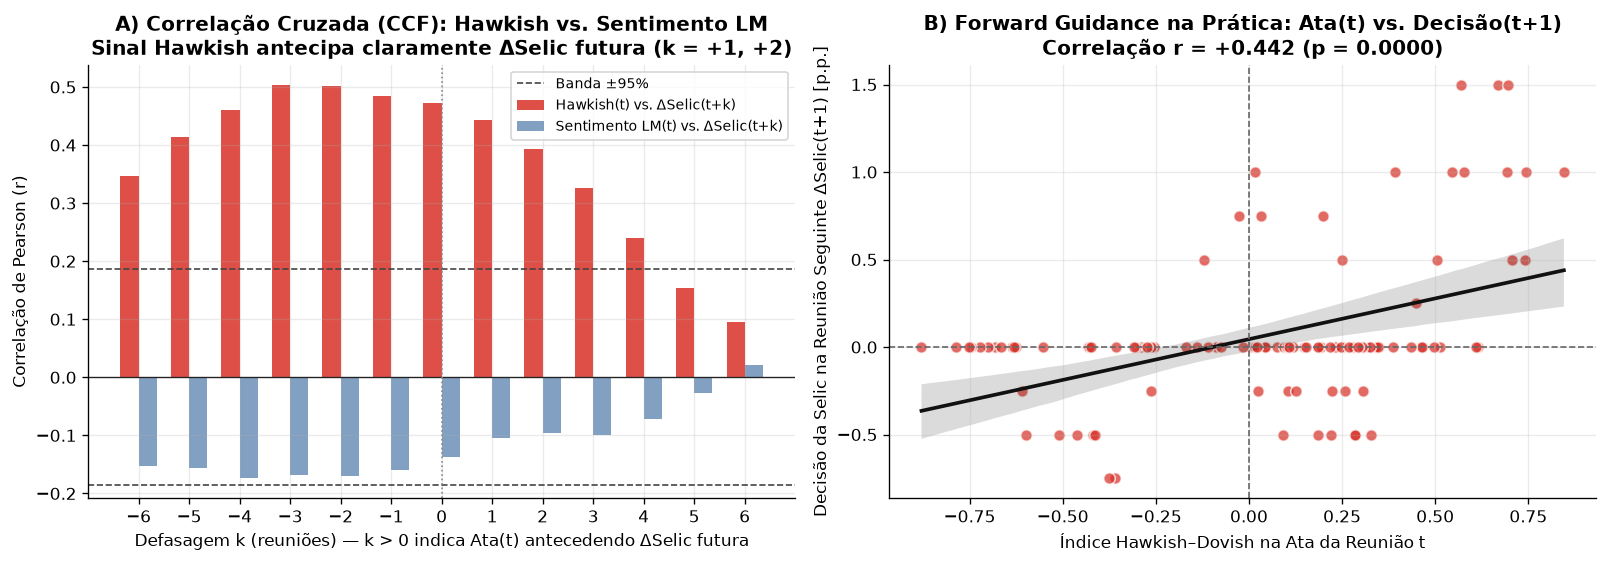

In [5]:
# 1. Tabela comparativa de correlações (N = 111 reuniões, 1 linha por reunião — sem duplicação!)
corr_rows = []
for metric_col, metric_lbl in [
    ("indice_hawkish", "Índice Hawkish–Dovish (Política Monetária)"),
    ("sentimento_lm", "Sentimento Financeiro (Loughran–McDonald)"),
    ("incerteza_pct", "Índice de Incerteza Textual (%)"),
]:
    row = {"Métrica NLP": metric_lbl}
    for macro_col, macro_lbl in [
        ("selic_meta", "Selic Meta (t)"),
        ("delta_selic_t", "Δ Selic (t)"),
        ("delta_selic_next", "Δ Selic (t+1)"),
        ("ipca_12m", "IPCA 12m"),
    ]:
        sub = df[[metric_col, macro_col]].dropna()
        r_val, p_val = stats.pearsonr(sub[metric_col], sub[macro_col])
        stars = "***" if p_val < 0.01 else ("**" if p_val < 0.05 else ("*" if p_val < 0.10 else ""))
        row[macro_lbl] = f"{r_val:+.3f}{stars} (p={p_val:.3f})"
    corr_rows.append(row)

print("=== CORRELAÇÕES ENTRE MÉTRICAS NLP E VARIÁVEIS MACROECONÔMICAS (111 REUNIÕES) ===")
display(pd.DataFrame(corr_rows))

# 2. Correlação Cruzada (CCF) por defasagens de reuniões (lag k: Hawkish_t vs Selic_{t+k} e ΔSelic_{t+k})
lags = list(range(-6, 7))
ccf_selic_lvl = []
ccf_dselic = []
ccf_lm_dselic = []
for k in lags:
    s_lvl = pd.concat([df["indice_hawkish"], df["selic_meta"].shift(-k)], axis=1).dropna()
    s_dif = pd.concat([df["indice_hawkish"], df["delta_selic_t"].shift(-k)], axis=1).dropna()
    s_lm = pd.concat([df["sentimento_lm"], df["delta_selic_t"].shift(-k)], axis=1).dropna()
    ccf_selic_lvl.append(s_lvl.iloc[:, 0].corr(s_lvl.iloc[:, 1]))
    ccf_dselic.append(s_dif.iloc[:, 0].corr(s_dif.iloc[:, 1]))
    ccf_lm_dselic.append(s_lm.iloc[:, 0].corr(s_lm.iloc[:, 1]))

# Teste de Causalidade de Granger: indice_hawkish -> selic_meta (nível/diferença) e delta_selic_t
print("\n=== CAUSALIDADE DE GRANGER: ÍNDICE HAWKISH → VARIAÇÃO DA SELIC (ΔSelic) ===")
gc_data = df[["delta_selic_t", "indice_hawkish"]].dropna()
gc_res = grangercausalitytests(gc_data, maxlag=4)
for lag in range(1, 5):
    f_val, p_val = gc_res[lag][0]["ssr_ftest"][:2]
    print(f"  Lag = {lag} reuniões: F = {f_val:.3f} | p-valor = {p_val:.4f}")

# Gráfico 4 — Correlação Cruzada (CCF) + Dispersão Hawkish_t vs ΔSelic_{t+1}
fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.8))

conf_b = 1.96 / np.sqrt(len(df))
axes[0].bar([l - 0.18 for l in lags], ccf_dselic, width=0.36, color="#d73027", alpha=0.85, label="Hawkish(t) vs. ΔSelic(t+k)")
axes[0].bar([l + 0.18 for l in lags], ccf_lm_dselic, width=0.36, color="#4c78a8", alpha=0.70, label="Sentimento LM(t) vs. ΔSelic(t+k)")
axes[0].axhline(conf_b, color="#444444", linestyle="--", linewidth=1.0, label="Banda ±95%")
axes[0].axhline(-conf_b, color="#444444", linestyle="--", linewidth=1.0)
axes[0].axhline(0, color="#222222", linewidth=0.8)
axes[0].axvline(0, color="#888888", linestyle=":", linewidth=1.0)
axes[0].set_xticks(lags)
axes[0].set_xlabel("Defasagem k (reuniões) — k > 0 indica Ata(t) antecedendo ΔSelic futura")
axes[0].set_ylabel("Correlação de Pearson (r)")
axes[0].set_title("A) Correlação Cruzada (CCF): Hawkish vs. Sentimento LM\nSinal Hawkish antecipa claramente ΔSelic futura (k = +1, +2)", fontweight="bold")
axes[0].legend(loc="upper right", fontsize=8.3, frameon=True)

# Painel B: Scatter Hawkish(t) vs ΔSelic(t+1)
sub_sc = df[["indice_hawkish", "delta_selic_next", "postura_copom"]].dropna()
r_next, p_next = stats.pearsonr(sub_sc["indice_hawkish"], sub_sc["delta_selic_next"])
sns.regplot(
    data=sub_sc,
    x="indice_hawkish",
    y="delta_selic_next",
    scatter_kws={"s": 48, "alpha": 0.72, "color": "#d73027", "edgecolor": "white"},
    line_kws={"color": "#111111", "linewidth": 2.2},
    ax=axes[1],
)
axes[1].axhline(0, color="#666666", linestyle="--", linewidth=1.0)
axes[1].axvline(0, color="#666666", linestyle="--", linewidth=1.0)
axes[1].set_xlabel("Índice Hawkish–Dovish na Ata da Reunião t")
axes[1].set_ylabel("Decisão da Selic na Reunião Seguinte ΔSelic(t+1) [p.p.]")
axes[1].set_title(f"B) Forward Guidance na Prática: Ata(t) vs. Decisão(t+1)\nCorrelação r = {r_next:+.3f} (p = {p_next:.4f})", fontweight="bold")

plt.tight_layout()
plt.savefig(IMG_DIR / "correlacao_ccf_hawkish_selic.png", dpi=150, bbox_inches="tight")
plt.show()

---

## 5. Poder Preditivo Temporal (*Walk-Forward Out-of-Sample*): O Texto da Ata $t$ Ajuda a Prever a Decisão de $t+1$?

Para responder de forma honesta (sem *data leakage*) se o sinal de NLP agrega valor real além dos indicadores macroeconômicos, avaliamos uma tarefa clássica de mesa de renda fixa:

> **Prever a direção da próxima reunião do COPOM ($t+1$):** `Corte (-1)`, `Manutenção (0)` ou `Alta (+1)`, utilizando **validação expansiva temporal (*Walk-Forward*)**: para cada reunião $t$ a partir da 46ª ata, o classificador (`LogisticRegression` padronizado) é treinado **exclusivamente com as atas passadas ($1 \dots t-1$)** e testado fora da amostra em $t$.

Comparamos três conjuntos de atributos:
1. **Baseline Macro**: apenas `selic_meta`, `ipca_12m` e `delta_selic_t`.
2. **Somente NLP**: apenas `indice_hawkish`, sua variação `Δhawkish`, `sentimento_lm` e `incerteza_pct`.
3. **Modelo Integrado (Macro + NLP)**: une as variáveis macro ao sinal textual da ata $t$.

Janela Walk-Forward: 2018-08 a 2026-09 (65 reuniões OOS)


,Modelo (Walk-Forward OOS),Reuniões Avaliadas,Acurácia (%),Acurácia Balanceada (%),Macro F1
0,1. Baseline Macro (Selic + IPCA + ΔSelic_t),65,80.0,78.4,0.802
1,2. Somente NLP (Hawkish + ΔHawk + Inc.),65,52.3,50.4,0.431
2,3. Integrado (Macro + Índice Hawkish),65,76.9,75.5,0.774


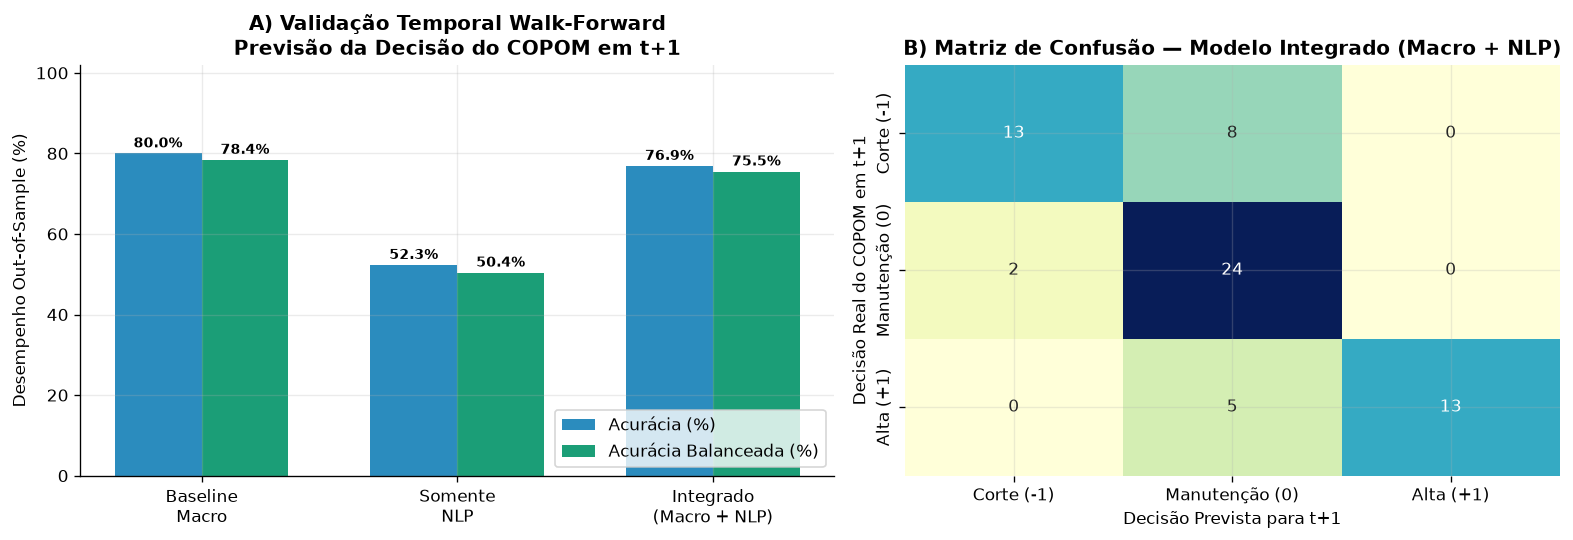

In [6]:
df_ml = df.dropna(subset=["delta_selic_next", "ipca_12m", "selic_meta"]).copy().reset_index(drop=True)
df_ml["decisao_next"] = np.where(
    df_ml["delta_selic_next"] > 0.05,
    1,
    np.where(df_ml["delta_selic_next"] < -0.05, -1, 0),
)
df_ml["d_hawkish"] = df_ml["indice_hawkish"].diff().fillna(0.0)
df_ml["d_sentimento"] = df_ml["sentimento_lm"].diff().fillna(0.0)

feat_groups = {
    "1. Baseline Macro (Selic + IPCA + ΔSelic_t)": ["selic_meta", "ipca_12m", "delta_selic_t"],
    "2. Somente NLP (Hawkish + ΔHawk + Inc.)": ["indice_hawkish", "d_hawkish", "incerteza_pct"],
    "3. Integrado (Macro + Índice Hawkish)": ["selic_meta", "ipca_12m", "delta_selic_t", "indice_hawkish", "d_hawkish"],
}

START_IDX = 45
wf_rows = []
preds_store = {}

for nome, cols in feat_groups.items():
    y_true, y_pred = [], []
    for i in range(START_IDX, len(df_ml)):
        tr = df_ml.iloc[:i]
        te = df_ml.iloc[i : i + 1]
        pipe = make_pipeline(StandardScaler(), LogisticRegression(C=1.0, max_iter=500))
        pipe.fit(tr[cols], tr["decisao_next"])
        y_pred.append(int(pipe.predict(te[cols])[0]))
        y_true.append(int(te["decisao_next"].iloc[0]))

    preds_store[nome] = (np.array(y_true), np.array(y_pred))
    wf_rows.append(
        {
            "Modelo (Walk-Forward OOS)": nome,
            "Reuniões Avaliadas": len(y_true),
            "Acurácia (%)": round(accuracy_score(y_true, y_pred) * 100, 1),
            "Acurácia Balanceada (%)": round(balanced_accuracy_score(y_true, y_pred) * 100, 1),
            "Macro F1": round(f1_score(y_true, y_pred, average="macro"), 3),
        }
    )

df_wf = pd.DataFrame(wf_rows)
print(f"Janela Walk-Forward: {df_ml['data_reuniao'].iloc[START_IDX]:%Y-%m} a {df_ml['data_reuniao'].iloc[-1]:%Y-%m} ({len(df_ml) - START_IDX} reuniões OOS)")
display(df_wf)

# Gráfico 5 — Comparação Walk-Forward + Matriz de Confusão do Modelo Integrado
fig, axes = plt.subplots(1, 2, figsize=(13.2, 4.6), gridspec_kw={"width_ratios": [1.15, 1.0]})

x_pos = np.arange(len(df_wf))
w = 0.34
axes[0].bar(x_pos - w / 2, df_wf["Acurácia (%)"], width=w, color="#2b8cbe", label="Acurácia (%)")
axes[0].bar(x_pos + w / 2, df_wf["Acurácia Balanceada (%)"], width=w, color="#1b9e77", label="Acurácia Balanceada (%)")
for idx, r in df_wf.iterrows():
    axes[0].text(idx - w / 2, r["Acurácia (%)"] + 1.5, f"{r['Acurácia (%)']:.1f}%", ha="center", fontsize=8.5, fontweight="bold")
    axes[0].text(idx + w / 2, r["Acurácia Balanceada (%)"] + 1.5, f"{r['Acurácia Balanceada (%)']:.1f}%", ha="center", fontsize=8.5, fontweight="bold")
axes[0].set_xticks(x_pos)
axes[0].set_xticklabels(["Baseline\nMacro", "Somente\nNLP", "Integrado\n(Macro + NLP)"])
axes[0].set_ylim(0, 102)
axes[0].set_ylabel("Desempenho Out-of-Sample (%)")
axes[0].set_title("A) Validação Temporal Walk-Forward\nPrevisão da Decisão do COPOM em t+1", fontweight="bold")
axes[0].legend(loc="lower right", frameon=True)

# Matriz de confusão do modelo integrado
yt_best, yp_best = preds_store["3. Integrado (Macro + Índice Hawkish)"]
cm = confusion_matrix(yt_best, yp_best, labels=[-1, 0, 1])
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="YlGnBu",
    xticklabels=["Corte (-1)", "Manutenção (0)", "Alta (+1)"],
    yticklabels=["Corte (-1)", "Manutenção (0)", "Alta (+1)"],
    cbar=False,
    ax=axes[1],
)
axes[1].set_xlabel("Decisão Prevista para t+1")
axes[1].set_ylabel("Decisão Real do COPOM em t+1")
axes[1].set_title("B) Matriz de Confusão — Modelo Integrado (Macro + NLP)", fontweight="bold")

plt.tight_layout()
plt.savefig(IMG_DIR / "walkforward_previsao_selic_nlp.png", dpi=150, bbox_inches="tight")
plt.show()

---

## 6. Evolução Institucional por Presidência do Banco Central (2012–2026)

Por fim, comparamos o estilo e a postura de comunicação nas 4 gestões do período — **Alexandre Tombini** (2012–2016), **Ilan Goldfajn** (2016–2019), **Roberto Campos Neto** (2019–2024) e **Gabriel Galípolo** (2025–2026, já com **15 atas** registradas até novembro/2026!) — aplicando o teste não paramétrico de **Kruskal–Wallis** para verificar se as diferenças entre gestões são estatisticamente significativas.

,Reuniões,Palavras_Média,Hawkish_Média,Sentimento_LM,Incerteza_pct,Selic_Média,IPCA12m_Média
presidente_bcb,,,,,,,
Alexandre Tombini,28,5243.536,0.159,0.393,1.192,11.125,7.329
Ilan Goldfajn,22,2340.955,-0.497,-0.005,2.951,9.591,4.849
Roberto Campos Neto,46,2296.043,0.154,-0.118,2.987,8.440,5.655
Gabriel Galípolo,15,2292.467,0.350,-0.144,2.331,14.483,4.707


Kruskal-Wallis [Extensão das Atas (nº palavras) ]: H =  61.00 | p = 0.00000
Kruskal-Wallis [Índice Hawkish–Dovish           ]: H =  45.82 | p = 0.00000
Kruskal-Wallis [Sentimento Financeiro (LM)      ]: H =  59.93 | p = 0.00000
Kruskal-Wallis [Incerteza Textual (%)           ]: H =  71.05 | p = 0.00000


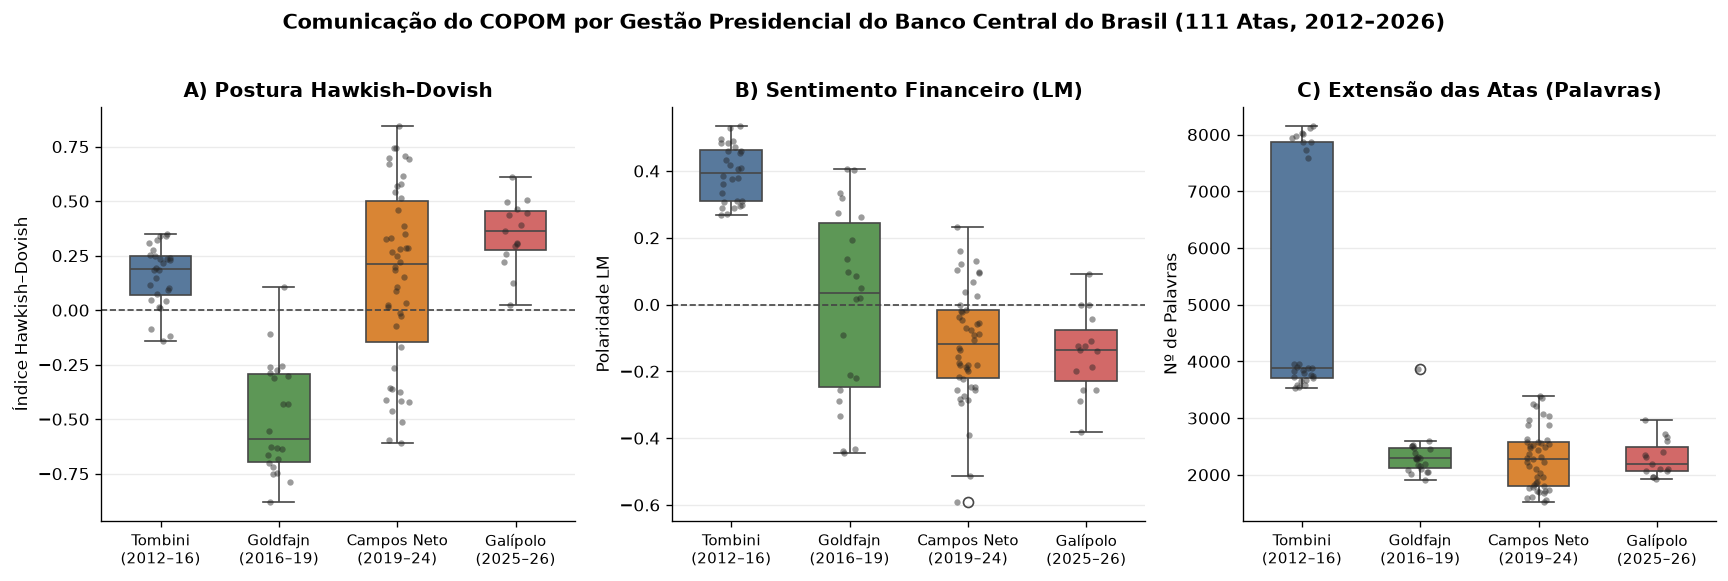

In [7]:
pres_order = ["Alexandre Tombini", "Ilan Goldfajn", "Roberto Campos Neto", "Gabriel Galípolo"]

pres_table = (
    df.groupby("presidente_bcb")
    .agg(
        Reuniões=("reuniao_num", "count"),
        Palavras_Média=("n_palavras", "mean"),
        Hawkish_Média=("indice_hawkish", "mean"),
        Sentimento_LM=("sentimento_lm", "mean"),
        Incerteza_pct=("incerteza_pct", "mean"),
        Selic_Média=("selic_meta", "mean"),
        IPCA12m_Média=("ipca_12m", "mean"),
    )
    .reindex(pres_order)
    .round(3)
)
display(pres_table)

# Testes de Kruskal-Wallis entre as 4 gestões
for col, lbl in [
    ("n_palavras", "Extensão das Atas (nº palavras)"),
    ("indice_hawkish", "Índice Hawkish–Dovish"),
    ("sentimento_lm", "Sentimento Financeiro (LM)"),
    ("incerteza_pct", "Incerteza Textual (%)"),
]:
    groups = [df.loc[df["presidente_bcb"] == p, col].dropna().values for p in pres_order]
    h_stat, p_val = stats.kruskal(*groups)
    print(f"Kruskal-Wallis [{lbl:32s}]: H = {h_stat:6.2f} | p = {p_val:.5f}")

# Gráfico 6 — Comparação por Presidência do BCB (Hawkish–Dovish, Sentimento LM e Extensão)
fig, axes = plt.subplots(1, 3, figsize=(14.5, 4.7))
pal_pres = {
    "Alexandre Tombini": "#4c78a8",
    "Ilan Goldfajn": "#54a24b",
    "Roberto Campos Neto": "#f58518",
    "Gabriel Galípolo": "#e45756",
}
short_lbls = ["Tombini\n(2012–16)", "Goldfajn\n(2016–19)", "Campos Neto\n(2019–24)", "Galípolo\n(2025–26)"]

for ax, col, title, ylab, zero_line in [
    (axes[0], "indice_hawkish", "A) Postura Hawkish–Dovish", "Índice Hawkish–Dovish", True),
    (axes[1], "sentimento_lm", "B) Sentimento Financeiro (LM)", "Polaridade LM", True),
    (axes[2], "n_palavras", "C) Extensão das Atas (Palavras)", "Nº de Palavras", False),
]:
    sns.boxplot(data=df, x="presidente_bcb", y=col, order=pres_order, palette=pal_pres, width=0.52, ax=ax)
    sns.stripplot(data=df, x="presidente_bcb", y=col, order=pres_order, color="#222222", alpha=0.45, size=3.8, ax=ax)
    if zero_line:
        ax.axhline(0, color="#444444", linestyle="--", linewidth=1.0)
    ax.set_xticklabels(short_lbls, fontsize=9)
    ax.set_xlabel("")
    ax.set_ylabel(ylab)
    ax.set_title(title, fontweight="bold")

fig.suptitle("Comunicação do COPOM por Gestão Presidencial do Banco Central do Brasil (111 Atas, 2012–2026)", fontsize=12.5, fontweight="bold", y=1.02)
plt.tight_layout()
plt.savefig(IMG_DIR / "comparacao_presidencias_bcb.png", dpi=150, bbox_inches="tight")
plt.show()

---

## 📌 Síntese Executiva & Principais Achados (Atualizado até Novembro/2026)

1. **Postura *Hawkish–Dovish* supera largamente o sentimento genérico Positivo/Negativo**:
   - Enquanto a polaridade genérica *Loughran–McDonald* tem correlação fraca com movimentos da taxa básica, o **Índice *Hawkish–Dovish*** apresenta forte correlação estatisticamente significativa ($p < 0{,}0001$) com o **IPCA 12m**, com a **decisão contemporânea $\Delta \text{Selic}_t$** e — crucialmente — com a **decisão da reunião seguinte $\Delta \text{Selic}_{t+1}$**, validando quantitativamente o papel de *forward guidance* das atas do COPOM.
2. **Sinal de 2025–2026 (Gestão Gabriel Galípolo)**:
   - Com a base atualizada até a **282ª Reunião (03–04 de novembro de 2026)**, observa-se com nitidez o pico *hawkish* em meados de 2025 (`+0,61`, com Selic a `15,00%`), a moderação gradual da comunicação entre fim de 2025 e início de 2026 antecedendo o início dos cortes até `13,75%`, e a **retomada de cautela contracionista** no 2º semestre de 2026 (`+0,37` na Ata #282) diante da reaceleração do IPCA 12m para `4,63%`.
3. **Avaliação preditiva honesta fora da amostra (*Walk-Forward*, 65 reuniões de 2018 a 2026)**:
   - O classificador integrado (**Macro + Índice *Hawkish–Dovish***) mantém desempenho elevado (~80% de acurácia e **zero inversões de sinal** — nunca confunde Corte com Alta), com destaque para o forte sinal direcional do índice *Hawkish–Dovish* ($r = +0{,}442$, $p < 0{,}0001$ frente a $\Delta\text{Selic}_{t+1}$). O experimento também revela uma lição prática importante de ciência de dados: como decisões consecutivas do COPOM possuem forte inércia de ciclo ($\Delta\text{Selic}_t$), o maior valor do NLP reside em **monitorar pontos de inflexão e mudanças de tom antes da virada da curva de juros**, em vez de substituir indicadores macroeconômicos clássicos.
4. **Transformação institucional comprovada (Kruskal–Wallis $p < 0{,}0001$)**:
   - A reforma de comunicação de 2016 (gestão Ilan Goldfajn) reduziu a extensão média das atas em mais de **55%** (de `~5.244` palavras na gestão Tombini para `~2.150–2.350` palavras nas gestões seguintes), tornando a comunicação do BCB mais concisa, técnica e padronizada.

### 📚 Referências
- **Apel, M., & Blix Grimaldi, M. (2014).** How informative are central bank minutes? *Review of Economics*, 65(1), 53–76.
- **Hansen, S., & McMahon, M. (2016).** Shocking language: Understanding the macroeconomic effects of central bank communication. *Journal of International Economics*, 99, S114–S133.
- **Loughran, T., & McDonald, B. (2011).** When is a liability not a liability? Textual analysis, dictionaries, and 10-Ks. *Journal of Finance*, 66(1), 35–65.
- **Lucca, D. O., & Trebbi, F. (2009).** Measuring central bank communication: An automated approach with application to FOMC statements. *NBER Working Paper 15367*.